# Topic modelling on reasoning traces — base version

**Goal.** Group sentences from model reasoning traces into a few topics, then look at what those topics contain.

This is a first, deliberately simple pipeline over all five runs (gpt-oss low/medium/high,
DeepSeek high/max). The fuller analysis lives in `trace_topics.ipynb`
(prompt-copy filtering, 40 topics, reasoning-move codebook, flip analysis).

**Pipeline (what we do)**

1. Load page-level traces from each run’s `output/.../<run_id>/reasoning_traces/*.jsonl`.
2. Split each reasoning text into sentences.
3. Embed unique sentences with a small local model (`all-MiniLM-L6-v2`).
4. Fit a small **BERTopic** model (UMAP → k-means, fixed number of topics).
5. Inspect each topic via keywords + example sentences.
6. Compare how often topics appear across runs.

## 0. Setup

Paths point at the current run folders under `output/`. Traces are read from `reasoning_traces/`.

In [ ]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

ROOT = Path.cwd().resolve()
if not (ROOT / "output").is_dir():
    ROOT = ROOT.parent

OUT = ROOT / "output"
DERIVED = ROOT / "analysis" / "derived"
SEED = 42
N_TOPICS = 10  # same setting as the bertopic10 Excel / review export
EMBED_MODEL = "all-MiniLM-L6-v2"
DS = "DeepSeek-V4-Flash-0731"

RUN_DIRS = {
    "gpt-oss low": OUT / "gpt-oss-120b_low" / "1ebb0c8dc26d4681bda9555908104e67",
    "gpt-oss medium": OUT / "gpt-oss-120b_medium" / "8b438992f14c4b6da28ec581572dcc85",
    "gpt-oss high": OUT / "gpt-oss-120b_high" / "10d7970dd8304f8cb06d174a851f8e2a",
    "DeepSeek high": OUT / f"{DS}_high" / "2c50bb4fcde3462f9d6cbe6516b686c9",
    "DeepSeek max": OUT / f"{DS}_max" / "4c3229ed86dc4fe6b1ef4b95c64ca68d",
}
KEEP_RUNS = list(RUN_DIRS)

## 1. Load traces

Each row is one page call from `reasoning_traces/*.jsonl`. Rows without reasoning text are dropped.

In [19]:
rows = []
for run, run_dir in RUN_DIRS.items():
    for path in sorted((run_dir / "reasoning_traces").glob("*.jsonl")):
        with path.open(encoding="utf-8") as f:
            for i, line in enumerate(f):
                c = json.loads(line)
                reasoning = c.get("reasoning_content")
                if not reasoning or not str(reasoning).strip():
                    continue
                rows.append({
                    "run": run,
                    "report": Path(str(c["pdf"]).replace("\\", "/")).name,
                    "call_index": i,
                    "reasoning": reasoning,
                    "answer": c.get("content"),
                })

pages = pd.DataFrame(rows)
pages["run"] = pd.Categorical(pages["run"], KEEP_RUNS, ordered=True)
pages["trace_id"] = np.arange(len(pages))

print(f"{len(pages):,} traces")
display(pages.groupby("run", observed=True).size().rename("traces").to_frame())
display(pages[["run", "report", "call_index", "reasoning"]].head(2))

4,858 traces


,traces
run,
gpt-oss low,973
gpt-oss medium,973
gpt-oss high,973
DeepSeek high,972
DeepSeek max,967


,run,report,call_index,reasoning
0,gpt-oss low,Allianz_2022_report.pdf,0,"We need extract scope values. In excerpt only business travel GHG emissions given, not total company. No total scope values. So output e..."
1,gpt-oss low,Allianz_2022_report.pdf,1,"We need extract values for 2020-2022 (within 2013-2024). Provide entries for each scope and year.\n\nFrom table: Scope1 values: 2022 30,..."


## 2. Split reasoning into sentences

Topic models work better on short units. Whole traces mostly differ by *page content*;
sentences are closer to individual reasoning steps.

We split on line breaks and on `.?!` followed by a capital letter / quote, and drop tiny fragments.

In [20]:
SPLIT = re.compile(r"\n+|(?<=[.!?])\s+(?=[A-Z\"'(\[])")


def sentences(text: str) -> list[str]:
    out = []
    for part in SPLIT.split(text or ""):
        part = re.sub(r"\s+", " ", part).strip(" -*•\t")
        if len(part.split()) >= 3:
            out.append(part)
    return out


seg = pd.DataFrame(
    [
        (row.trace_id, row.run, i, text)
        for row in pages.itertuples()
        for i, text in enumerate(sentences(row.reasoning))
    ],
    columns=["trace_id", "run", "pos", "text"],
)

print(f"{len(seg):,} sentences  |  {seg.text.nunique():,} unique")
display(
    pd.DataFrame({
        "sentences": seg.groupby("run", observed=True).size(),
        "median per trace": seg.groupby(["run", "trace_id"], observed=True).size()
            .groupby("run", observed=True).median(),
    })
)
display(seg.head(5))

226,557 sentences  |  130,169 unique


,sentences,median per trace
run,,
DeepSeek high,44536,11.0
DeepSeek max,67287,13.0
gpt-oss high,97973,43.0
gpt-oss low,3728,2.0
gpt-oss medium,13033,10.0


,trace_id,run,pos,text
0,0,gpt-oss low,0,We need extract scope values.
1,0,gpt-oss low,1,"In excerpt only business travel GHG emissions given, not total company."
2,0,gpt-oss low,2,No total scope values.
3,0,gpt-oss low,3,So output empty list.
4,1,gpt-oss low,0,We need extract values for 2020-2022 (within 2013-2024).


## 3. Embed sentences

We convert each *unique* sentence into a vector with `SentenceTransformer`.
Similar meaning → similar vectors. That is the input for clustering.

No API calls: the model runs locally.

In [21]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL)
uniq = seg.text.drop_duplicates().tolist()
E = embedder.encode(uniq, batch_size=256, normalize_embeddings=True, show_progress_bar=True)

sent = pd.DataFrame({"text": uniq})
print(f"embedding matrix: {E.shape[0]:,} sentences × {E.shape[1]} dims")

Batches: 100%|██████████| 509/509 [03:51<00:00,  2.20it/s]


embedding matrix: 130,169 sentences × 384 dims


## 4. Topic model with BERTopic

**Idea.** Put similar sentence vectors into the same group, then label each group with keywords.

We use BERTopic with:
- the MiniLM embeddings from above
- UMAP to reduce dimensionality
- **k-means** (instead of HDBSCAN) with fixed `N_TOPICS`, so every sentence gets a topic
- KeyBERT-style keywords for readable topic labels

This is the same core as `trace_topics.ipynb`, just with fewer topics and no prompt-copy filter yet.

In [22]:
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

docs = sent["text"].tolist()

topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=UMAP(
        n_neighbors=15, n_components=5, min_dist=0.0,
        metric="cosine", random_state=SEED,
    ),
    # BERTopic expects this argument name even when we pass k-means.
    hdbscan_model=KMeans(n_clusters=N_TOPICS, random_state=SEED, n_init=10),
    vectorizer_model=CountVectorizer(
        stop_words="english", ngram_range=(1, 2), min_df=5,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
    ),
    representation_model=KeyBERTInspired(),
    calculate_probabilities=False,
)

topics, _ = topic_model.fit_transform(docs, E)
sent["topic"] = topics

info = topic_model.get_topic_info()
topic_info = pd.DataFrame({
    "topic": info.Topic,
    "n": info.Count,
    "keywords": info.Representation.map(lambda w: ", ".join(w[:8])),
})
display(topic_info)

# Attach topic labels back to every sentence occurrence in the traces.
seg = seg.drop(columns=[c for c in ["topic"] if c in seg.columns], errors="ignore")
seg = seg.merge(sent[["text", "topic"]], on="text", how="left")
print(f"{seg.topic.nunique()} topics on {len(seg):,} sentence occurrences")

,topic,n,keywords
0,0,25354,"sum scopes, extract values, scope scope, scope emissions, scope, scopes, values, emissions scope"
1,1,18579,"year range, values year, year values, values years, include year, year need, numbers, fiscal year"
2,2,17951,"extract values, values, values refer, company excerpt, total company, value, extract, says extract"
3,3,16565,"company scope, entries, scope company, total scope, scope total, company, says extract, scope need"
4,4,14798,"values excerpt, values need, values, calculations, extract values, values based, excerpt, year value"
5,5,13359,"scope total, total scope, emissions total, approx million, value, million tons, total emissions, values"
6,6,8788,"extract absolute, extract values, values, value unit, says extract, value, need extract, extract"
7,7,7000,"scope, tons scope, values, unit thousand, value, thousand, numbers, thousand tonnes"
8,8,6146,"unit year, values, year, year location-based, value, numbers, metric names, metric"
9,9,1629,"year value, extract values, extract value, values available, values, scope extract, scope value, unit year"


10 topics on 226,557 sentence occurrences


## 5. What do these topics mean?

BERTopic does **not** know what “reasoning” is. It only groups sentences that are
*lexically / semantically similar*. So a topic is just a cluster of similar sentences.

**How to read a topic**
1. Look at the **keywords** — frequent distinctive words in that cluster.
2. Read the **example sentences** — they matter more than the keywords.
3. Give the cluster a short **human label** in your own words.

Labels below are interpretive (from keywords + examples), not ground truth.
With **10 topics**, some clusters overlap or mix several reasoning moves — still useful for browsing and for matching the Excel export.

After re-fitting, read the printed examples and fill `TOPIC_LABELS` in the next cell.

| Topic | Proposed label | How safe? |
|---|---|---|
| 0 | *(fill after re-run)* | |
| 1 | *(fill after re-run)* | |
| 2 | *(fill after re-run)* | |
| 3 | *(fill after re-run)* | |
| 4 | *(fill after re-run)* | |
| 5 | *(fill after re-run)* | |
| 6 | *(fill after re-run)* | |
| 7 | *(fill after re-run)* | |
| 8 | *(fill after re-run)* | |
| 9 | *(fill after re-run)* | |

In [23]:
def show_topics(n_examples: int = 5) -> pd.DataFrame:
    kw = topic_info.set_index("topic")["keywords"]
    rows = []
    for topic, g in seg.groupby("topic"):
        examples = (
            g.drop_duplicates("text")
             .sample(min(n_examples, g.text.nunique()), random_state=SEED)
             .text.tolist()
        )
        rows.append({
            "topic": int(topic),
            "n": len(g),
            "n_unique": g.text.nunique(),
            "keywords": kw.get(topic, ""),
            "examples": examples,
        })
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)


topic_table = show_topics()

# Print one topic at a time — easier to interpret than a wide table.
for row in topic_table.itertuples():
    print("=" * 88)
    print(f"Topic {row.topic}  |  {row.n:,} sentences ({row.n_unique:,} unique)")
    print(f"keywords: {row.keywords}")
    for i, ex in enumerate(row.examples, 1):
        print(f"  {i}. {ex}")

# Human labels from keywords + example sentences (section 5).
# Placeholders until you re-run BERTopic with N_TOPICS=10 and rename from the examples.
TOPIC_LABELS = {
    0: "topic 0",
    1: "topic 1",
    2: "topic 2",
    3: "topic 3",
    4: "topic 4",
    5: "topic 5",
    6: "topic 6",
    7: "topic 7",
    8: "topic 8",
    9: "topic 9",
}

labeled = {t: TOPIC_LABELS.get(t, f"topic {t}") for t in topic_table.topic.astype(int)}
seg["topic_label"] = seg["topic"].map(labeled)
display(pd.DataFrame({
    "topic": list(labeled),
    "label": [labeled[t] for t in labeled],
    "keywords": topic_table.set_index("topic").reindex(labeled).keywords,
}))

Topic 4  |  36,906 sentences (14,798 unique)
keywords: values excerpt, values need, values, calculations, extract values, values based, excerpt, year value
  1. But we might also consider if the user expects a note that no data found.
  2. Now, we must consider if the user might want to see that no values were found.
  3. Excerpt is garbled but maybe contains hidden data?
  4. For example, the columns might be:
  5. Actually "INPUT" and "OUTPUT" maybe.
Topic 0  |  33,864 sentences (25,354 unique)
keywords: sum scopes, extract values, scope scope, scope emissions, scope, scopes, values, emissions scope
  1. But we need to double-check the instructions: "Only extract values which refer to the whole company." The manufacturing stage emissions might be for the manufacturing stage only, not the whole company.
  2. our carbon reduction goals
  3. Excerpt is methodology text, no actual numerical emissions values.
  4. The table might list "4.710 tCO2e" as "total emissions" and "22.8" as "tons

,topic,label,keywords
topic,,,
4,4,topic 4,"values excerpt, values need, values, calculations, extract values, values based, excerpt, year value"
0,0,topic 0,"sum scopes, extract values, scope scope, scope emissions, scope, scopes, values, emissions scope"
6,6,topic 6,"extract absolute, extract values, values, value unit, says extract, value, need extract, extract"
1,1,topic 1,"year range, values year, year values, values years, include year, year need, numbers, fiscal year"
3,3,topic 3,"company scope, entries, scope company, total scope, scope total, company, says extract, scope need"
2,2,topic 2,"extract values, values, values refer, company excerpt, total company, value, extract, says extract"
5,5,topic 5,"scope total, total scope, emissions total, approx million, value, million tons, total emissions, values"
8,8,topic 8,"unit year, values, year, year location-based, value, numbers, metric names, metric"
7,7,topic 7,"scope, tons scope, values, unit thousand, value, thousand, numbers, thousand tonnes"


## 6. Compare runs

Share of sentences per topic, by run (gpt-oss and DeepSeek).
If more reasoning effort changes *what* the model writes (not only *how much*),
the topic mix should shift — not only the total number of sentences.

Bars use your `TOPIC_LABELS` when filled in; otherwise topic IDs.

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
topic_label,,,,,
topic 4,46.7%,17.6%,15.0%,16.1%,16.4%
topic 0,19.5%,19.5%,13.6%,15.5%,15.3%
topic 6,2.7%,27.5%,11.4%,13.1%,12.5%
topic 1,8.7%,9.2%,11.9%,12.5%,12.6%
topic 3,13.3%,10.1%,10.0%,12.6%,11.7%
topic 2,2.2%,5.8%,11.3%,10.3%,9.8%
topic 5,3.3%,4.3%,9.4%,9.6%,10.0%
topic 8,0.0%,0.2%,14.3%,4.9%,5.0%
topic 7,3.6%,4.3%,2.4%,4.3%,5.4%


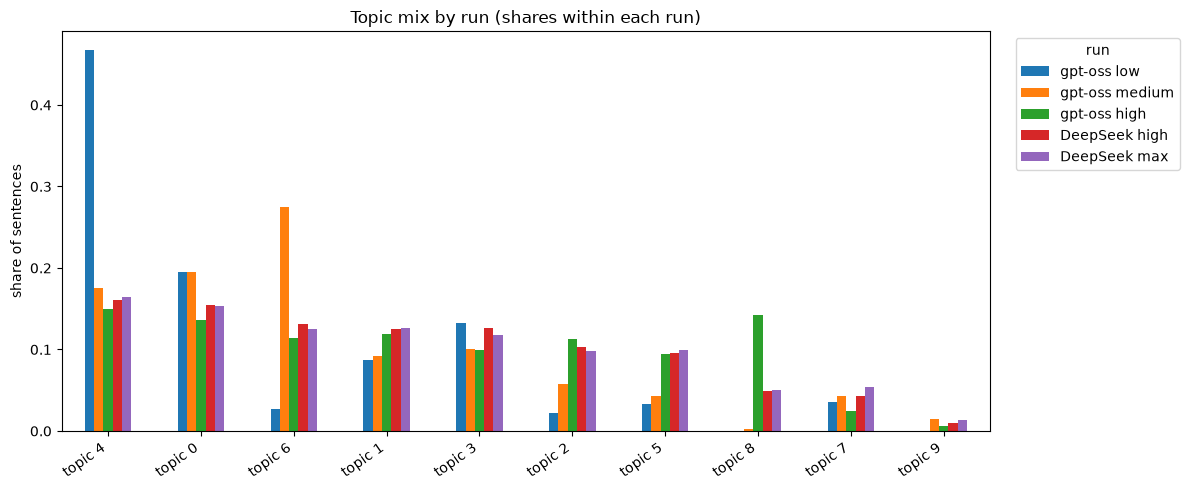

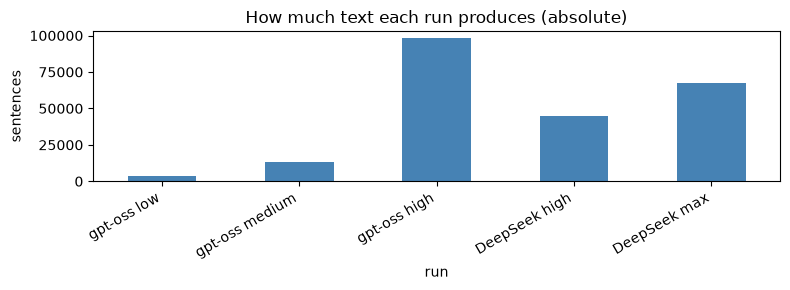

In [24]:
share = (
    seg.groupby(["run", "topic_label"], observed=True).size()
       .groupby("run", observed=True).transform(lambda s: s / s.sum())
       .rename("share")
       .reset_index()
)
# Keep topic order by size overall.
label_order = (
    seg.groupby("topic_label").size().sort_values(ascending=False).index.tolist()
)
pivot = (
    share.pivot(index="topic_label", columns="run", values="share")
         .fillna(0)
         .reindex(label_order)
         .reindex(columns=KEEP_RUNS)
)
display(pivot.style.format("{:.1%}"))

ax = pivot.plot(kind="bar", figsize=(12, 5))
ax.set_ylabel("share of sentences")
ax.set_xlabel("")
ax.set_title("Topic mix by run (shares within each run)")
ax.legend(title="run", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Sentence volume still differs a lot by run — show that separately.
vol = seg.groupby("run", observed=True).size().reindex(KEEP_RUNS)
ax = vol.plot(kind="bar", figsize=(8, 3), color="steelblue")
ax.set_ylabel("sentences")
ax.set_title("How much text each run produces (absolute)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 7. UMAP of topic groups

2D projection of the MiniLM embeddings, coloured by your `TOPIC_LABELS` (section 5).
Change the labels there, re-run that cell, then this plot.

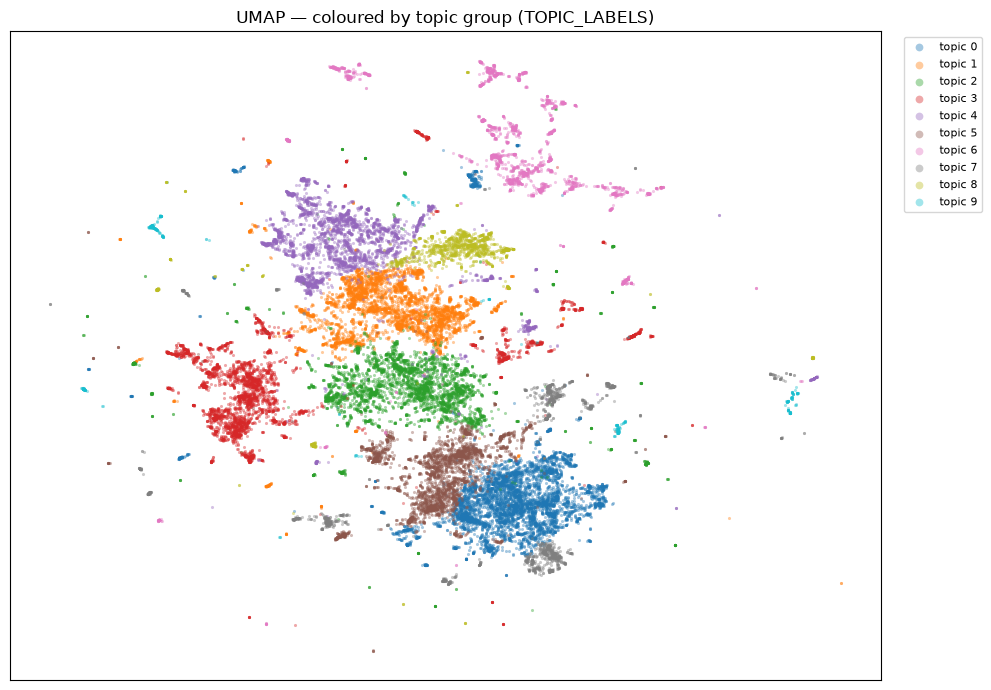

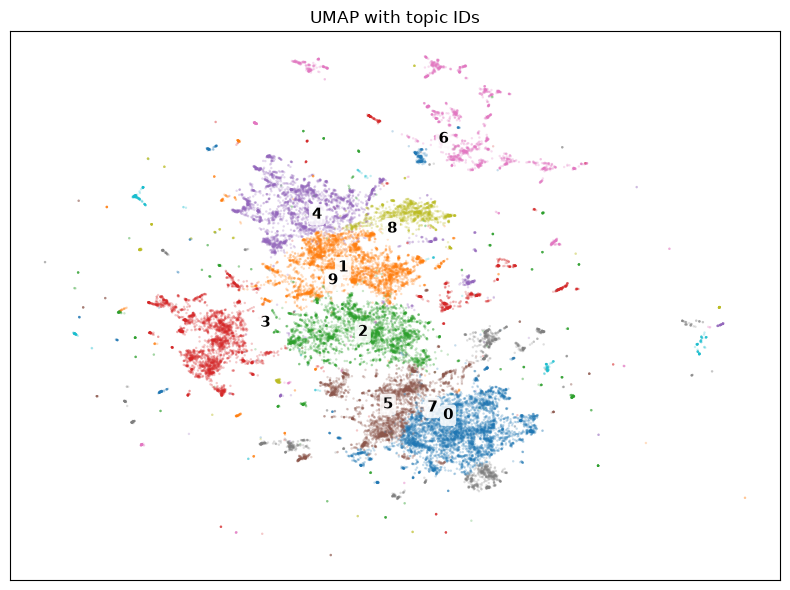

In [25]:
from umap import UMAP

DERIVED_TOPICS = DERIVED / "topics_base"
DERIVED_TOPICS.mkdir(parents=True, exist_ok=True)
umap_path = DERIVED_TOPICS / "umap2d.npy"

if umap_path.exists() and len(np.load(umap_path)) == len(E):
    xy = np.load(umap_path)
else:
    xy = UMAP(
        n_neighbors=15, n_components=2, min_dist=0.1,
        metric="cosine", random_state=SEED,
    ).fit_transform(E)
    np.save(umap_path, xy)

plot = sent[["text", "topic"]].copy()
plot["topic_label"] = plot["topic"].map(lambda t: TOPIC_LABELS.get(int(t), f"topic {t}"))
plot["x"], plot["y"] = xy[:, 0], xy[:, 1]

rng = np.random.default_rng(SEED)
idx = rng.choice(len(plot), size=min(30_000, len(plot)), replace=False)
sub = plot.iloc[idx]

labels = [TOPIC_LABELS[t] for t in sorted(TOPIC_LABELS)]
colors = plt.cm.tab10(np.linspace(0, 1, max(len(labels), 1)))
label_to_color = dict(zip(labels, colors))

fig, ax = plt.subplots(figsize=(10, 7))
for lab in labels:
    pts = sub[sub.topic_label == lab]
    if pts.empty:
        continue
    ax.scatter(pts.x, pts.y, s=5, alpha=0.4, linewidths=0,
               color=label_to_color[lab], label=lab)
ax.set_title("UMAP — coloured by topic group (TOPIC_LABELS)")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=2.5, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Topic ID centres on the same layout
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sub.x, sub.y, c=sub.topic, cmap="tab10", s=3, alpha=0.25, linewidths=0)
centres = plot.groupby("topic")[["x", "y"]].mean()
for t, row in centres.iterrows():
    ax.text(row.x, row.y, str(int(t)), fontsize=11, fontweight="bold",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.85, lw=0))
ax.set_title("UMAP with topic IDs")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()